In [11]:
# Import necessary libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans




# Load the dataset
df = pd.read_csv('Mall_Customers.csv')

# Display the first 5 rows
df.head()


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [12]:
# Overview of the dataset
df.info()

# Summary statistics for numerical columns
df.describe()

# Check for missing values
df.isnull().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [13]:
from sklearn.preprocessing import StandardScaler

# Select only numerical features relevant to clustering
features = df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']]

# Apply StandardScaler
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

# Convert scaled features back into a DataFrame for readability
scaled_df = pd.DataFrame(scaled_features, columns=features.columns)

scaled_df.head()


,Age,Annual Income (k$),Spending Score (1-100)
0,-1.424569,-1.738999,-0.434801
1,-1.281035,-1.738999,1.195704
2,-1.352802,-1.700830,-1.715913
3,-1.137502,-1.700830,1.040418
4,-0.563369,-1.662660,-0.395980


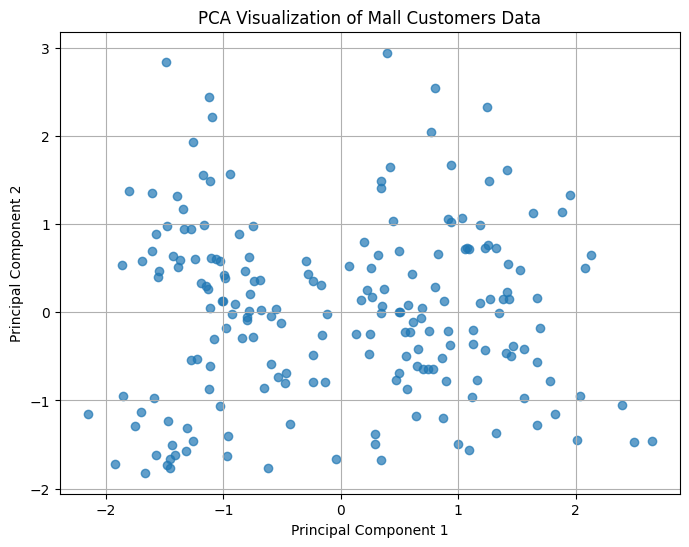

In [14]:
#b)
# Select features and standardize
features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
X = df[features]
X_scaled = StandardScaler().fit_transform(X)

# Apply PCA
X_pca = PCA(n_components=2).fit_transform(X_scaled)

# Plot
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.7)
plt.title('PCA Visualization of Mall Customers Data')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True)
plt.show()

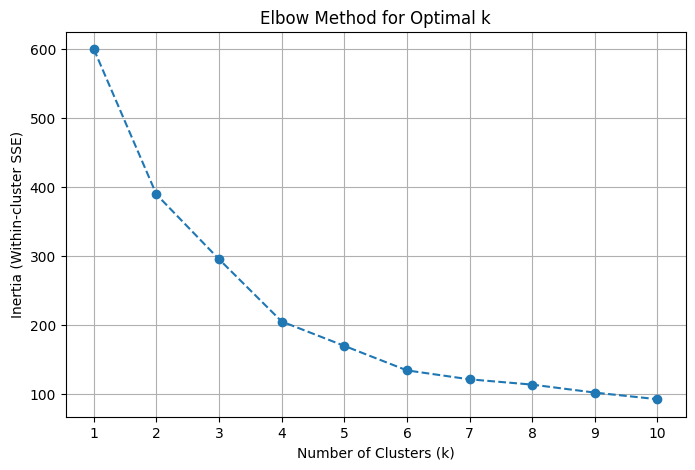

Inertia values: [599.9999999999999, 389.3861889564372, 295.4562449213556, 205.22514747675913, 169.89149793438582, 134.35277477401493, 121.38935022502872, 113.72723000071338, 102.13623844329254, 92.55027231838785]


In [15]:
#c
# Elbow Method
inertias = []
k_range = range(1, 11)  # Testing 1-10 clusters

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

# Plot the elbow curve
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertias, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-cluster SSE)')
plt.xticks(k_range)
plt.grid(True)
plt.show()

# Print inertia values for inspection
print("Inertia values:", inertias)

#K is equal to 6 based on the elbow method


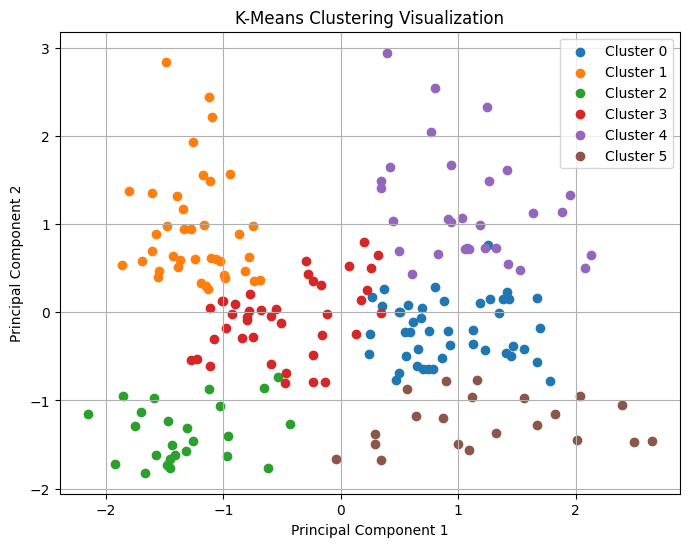

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,2
1,2,Male,21,15,81,2
2,3,Female,20,16,6,5
3,4,Female,23,16,77,2
4,5,Female,31,17,40,5


In [16]:
# d) Model Training with K-Means

# Train the K-Means model with the optimal number of clusters (k=6)
optimal_k = 6
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
kmeans.fit(X_scaled)

# Add the cluster labels to the original dataset
df['Cluster'] = kmeans.labels_

# Visualize the clusters in the PCA-reduced space
plt.figure(figsize=(8, 6))
for cluster in range(optimal_k):
    cluster_points = X_pca[df['Cluster'] == cluster]
    plt.scatter(cluster_points[:, 0], cluster_points[:, 1], label=f'Cluster {cluster}')

plt.title('K-Means Clustering Visualization')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.grid(True)
plt.show()

# Display the first few rows of the dataset with cluster labels
df.head()

In [19]:
# Cell 1: Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score
from IPython.display import display



In [22]:
# e.1) Agglomerative Hierarchical Clustering
print("="*80)
print(f"Agglomerative Hierarchical Clustering (k={optimal_k})")
print("="*80)

agg_cluster = AgglomerativeClustering(
    n_clusters=optimal_k,
    metric='euclidean',
    linkage='ward'
)
agg_labels = agg_cluster.fit_predict(scaled_features)

# Calculate metrics
agg_silhouette = silhouette_score(scaled_features, agg_labels)
agg_db = davies_bouldin_score(scaled_features, agg_labels)

print(f"Cluster labels: {np.unique(agg_labels)}")
print(f"\nSilhouette Score: {agg_silhouette:.3f}")
print(f"Davies-Bouldin Index: {agg_db:.3f}")



Agglomerative Hierarchical Clustering (k=6)
Cluster labels: [0 1 2 3 4 5]

Silhouette Score: 0.420
Davies-Bouldin Index: 0.852


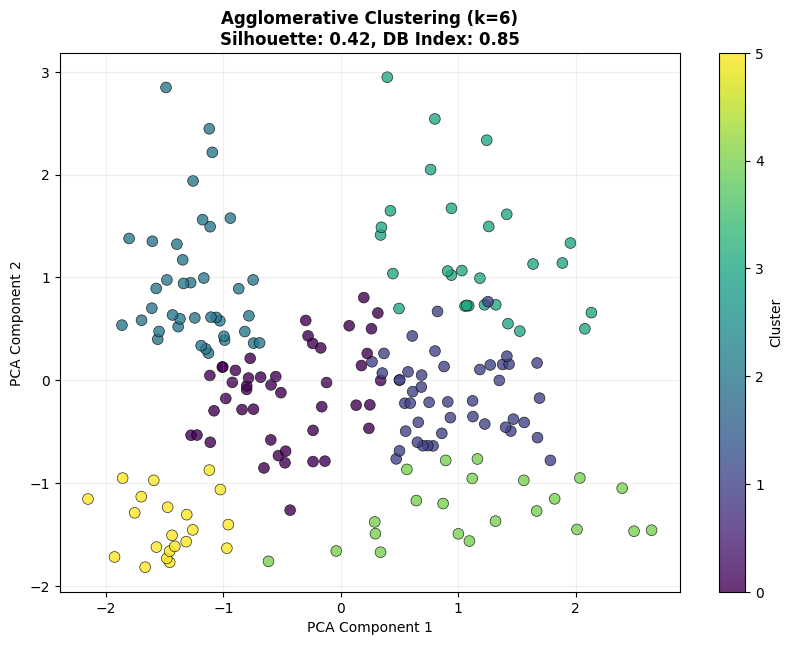

In [24]:
plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=agg_labels, cmap='viridis',
    s=60, alpha=0.8, edgecolor='k', linewidth=0.5
)
plt.title(f'Agglomerative Clustering (k={optimal_k})\nSilhouette: {agg_silhouette:.2f}, DB Index: {agg_db:.2f}',
          fontweight='bold')
plt.xlabel('PCA Component 1', fontsize=10)
plt.ylabel('PCA Component 2', fontsize=10)
plt.colorbar(scatter, ticks=range(optimal_k), label='Cluster')
plt.grid(alpha=0.2)
plt.show()


In [28]:
# e.2) Gaussian Mixture Model (GMM)
print("="*80)
print(f"Gaussian Mixture Model (k={optimal_k})")
print("="*80)

gmm = GaussianMixture(
    n_components=optimal_k,
    random_state=42,
    covariance_type='full'
)
gmm.fit(scaled_features)
gmm_labels = gmm.predict(scaled_features)
gmm_probs = gmm.predict_proba(scaled_features)

# Calculate metrics
gmm_silhouette = silhouette_score(scaled_features, gmm_labels)
gmm_db = davies_bouldin_score(scaled_features, gmm_labels)

print(f"Cluster labels: {np.unique(gmm_labels)}")
print("\nSoft clustering probabilities (first 5 samples):")
print(pd.DataFrame(gmm_probs[:5].round(3)))
print(f"\nSilhouette Score: {gmm_silhouette:.3f}")
print(f"Davies-Bouldin Index: {gmm_db:.3f}")


Gaussian Mixture Model (k=6)
Cluster labels: [0 1 2 3 4 5]

Soft clustering probabilities (first 5 samples):
     0    1      2      3    4      5
0  0.0  0.0  0.001  0.000  0.0  0.999
1  0.0  0.0  0.999  0.001  0.0  0.000
2  0.0  0.0  0.000  0.000  0.0  1.000
3  0.0  0.0  0.997  0.003  0.0  0.000
4  0.0  0.0  0.000  0.000  0.0  1.000

Silhouette Score: 0.400
Davies-Bouldin Index: 0.893


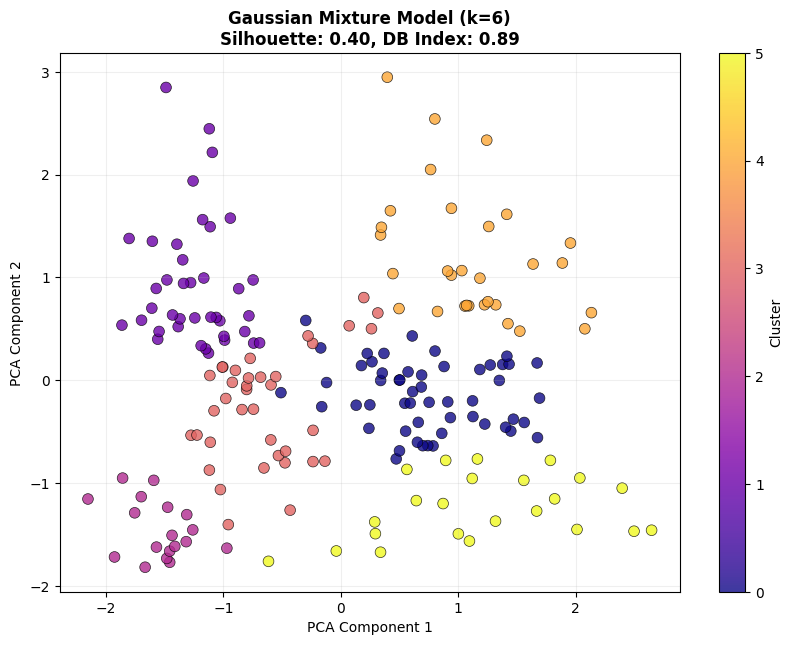

In [30]:
# Cell 5: GMM Visualization
plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=gmm_labels, cmap='plasma',
    s=60, alpha=0.8, edgecolor='k', linewidth=0.5
)
plt.title(f'Gaussian Mixture Model (k={optimal_k})\nSilhouette: {gmm_silhouette:.2f}, DB Index: {gmm_db:.2f}',
          fontweight='bold')
plt.xlabel('PCA Component 1', fontsize=10)
plt.ylabel('PCA Component 2', fontsize=10)
plt.colorbar(scatter, ticks=range(optimal_k), label='Cluster')
plt.grid(alpha=0.2)
plt.show()


In [32]:
# e.3) BIRCH Clustering

from sklearn.cluster import Birch

print("="*80)
print(f"BIRCH Clustering (k={optimal_k})")
print("="*80)

birch = Birch(
    n_clusters=optimal_k,
    threshold=0.5,
    branching_factor=50
)
birch_labels = birch.fit_predict(scaled_features)

# Calculate metrics
birch_silhouette = silhouette_score(scaled_features, birch_labels)
birch_db = davies_bouldin_score(scaled_features, birch_labels)

print(f"Cluster labels: {np.unique(birch_labels)}")
print(f"\nSilhouette Score: {birch_silhouette:.3f}")
print(f"Davies-Bouldin Index: {birch_db:.3f}")


BIRCH Clustering (k=6)
Cluster labels: [0 1 2 3 4 5]

Silhouette Score: 0.428
Davies-Bouldin Index: 0.840


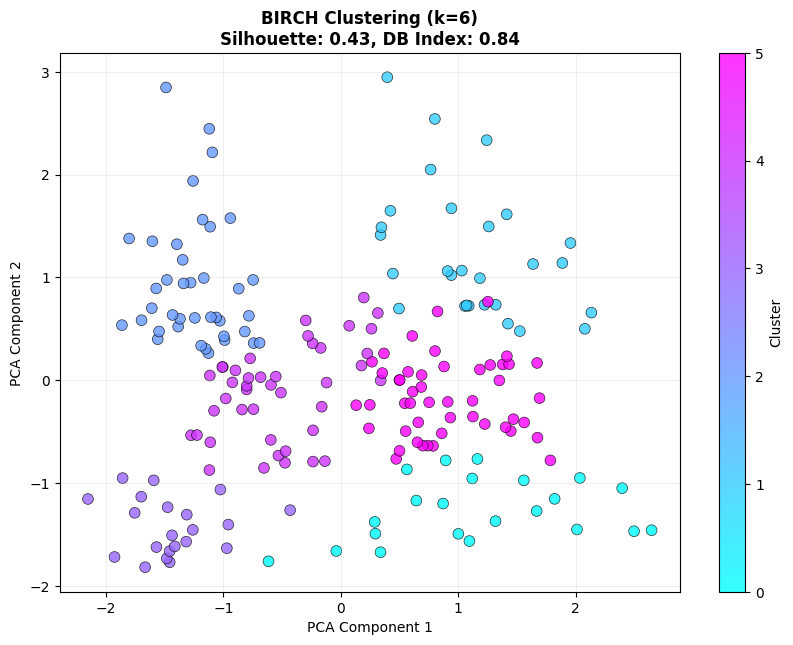

In [34]:
# Cell 7: BIRCH Clustering Visualization
plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=birch_labels, cmap='cool',
    s=60, alpha=0.8, edgecolor='k', linewidth=0.5
)
plt.title(f'BIRCH Clustering (k={optimal_k})\nSilhouette: {birch_silhouette:.2f}, DB Index: {birch_db:.2f}',
          fontweight='bold')
plt.xlabel('PCA Component 1', fontsize=10)
plt.ylabel('PCA Component 2', fontsize=10)
plt.colorbar(scatter, ticks=range(optimal_k), label='Cluster')
plt.grid(alpha=0.2)
plt.show()


In [35]:
# Cell 8: Comprehensive Comparison
print("="*80)
print("Clustering Algorithms Comparison")
print("="*80)

comparison = pd.DataFrame({
    'Algorithm': ['Agglomerative', 'GMM', 'BIRCH'],
    'Silhouette': [agg_silhouette, gmm_silhouette, birch_silhouette],
    'Davies-Bouldin': [agg_db, gmm_db, birch_db]
}).set_index('Algorithm')

def highlight_max(s):
    is_max = s == s.max()
    return ['background-color: #2ecc71' if v else '' for v in is_max]

def highlight_min(s):
    is_min = s == s.min()
    return ['background-color: #e74c3c' if v else '' for v in is_min]

styled_comparison = comparison.style\
    .format(precision=3)\
    .apply(highlight_max, subset=['Silhouette'])\
    .apply(highlight_min, subset=['Davies-Bouldin'])\
    .set_caption("Note: Higher Silhouette and Lower DB Index are better")

display(styled_comparison)

print("\nKey Insights:")
print("- Agglomerative: Creates hierarchical clusters, good for data with clear nested structures")
print("- GMM: Provides probabilistic assignments, ideal when clusters overlap")
print("- BIRCH: Efficient for large datasets, works well with spherical clusters")
print("\nRecommendation:")
print("For customer segmentation, consider which characteristics are most important:")
print("- Cluster purity (GMM)")
print("- Interpretable hierarchy (Agglomerative)")
print("- Computational efficiency (BIRCH)")

Clustering Algorithms Comparison


,Silhouette,Davies-Bouldin
Algorithm,,
Agglomerative,0.420,0.852
GMM,0.400,0.893
BIRCH,0.428,0.840



Key Insights:
- Agglomerative: Creates hierarchical clusters, good for data with clear nested structures
- GMM: Provides probabilistic assignments, ideal when clusters overlap
- BIRCH: Efficient for large datasets, works well with spherical clusters

Recommendation:
For customer segmentation, consider which characteristics are most important:
- Cluster purity (GMM)
- Interpretable hierarchy (Agglomerative)
- Computational efficiency (BIRCH)


In [ ]:
#h)
# Interpretation: Interpret your findings
# i need all the steps el awel 